# DSC212 ASSIGNMENT
## Modularity on the Karate Club Graph

**Name:** Noureen Rasheed Ullattuthodiyil

**Roll Number:** IMS25144

# INTRODUCTION
Community detection is an important problem in graph theory and network analysis. It involves identifying groups of nodes that are more densely connected to each other than to the rest of the network. These groups are called communities.

In this assignment, the famous Karate Club graph is used to study community structure. The graph represents friendships among members of a karate club and is one of the most widely used benchmark datasets for testing community detection algorithms.

A key concept in community detection is modularity, which measures the quality of a partition by comparing the actual number of edges within communities to the number expected in a random network. Higher modularity values indicate stronger community structure.

The objective of this assignment is to implement recursive spectral modularity partitioning to identify communities in the Karate Club graph. The assignment also investigates how node-level metrics such as degree centrality, betweenness centrality, closeness centrality, and clustering coefficient change as the graph is recursively partitioned.

The detected communities will be visualized after each partitioning step and the evolution of node metrics will be analyzed to understand how community structure influence the importance and connectivity of nodes within the network.


In [1]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import modularity as nx_modularity   

os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)
plt.rcParams["figure.dpi"] = 110
TOL = 1e-10      # numerical tolerance used for the test "lambda_1 <= 0"

def save_fig(name):
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

# 1. Loading the Karate Club Graph

$B = A - \dfrac{k k^\top}{2m}$, where $k$ is the degree vector and $m$ the number of edges.

In [2]:
G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n, m = G.number_of_nodes(), G.number_of_edges()
print(f"n = {n} nodes, m = {m} edges")

A = nx.to_numpy_array(G, nodelist=nodes, weight=None)   # adjacency matrix
k = A.sum(axis=1)                                        # degree vector
B = A - np.outer(k, k) / (2 * m)                         # global modularity matrix

# Sanity checks:
print("A is 0/1:", set(np.unique(A)) == {0.0, 1.0})
print("sum(k) = 2m:", k.sum() == 2 * m)
print("B symmetric:", np.allclose(B, B.T))
print("B @ 1 = 0:", np.allclose(B @ np.ones(n), 0))
print("Q of trivial partition:", round(float(np.ones(n) @ B @ np.ones(n) / (4 * m)), 12))

n = 34 nodes, m = 78 edges
A is 0/1: True
sum(k) = 2m: True
B symmetric: True
B @ 1 = 0: True
Q of trivial partition: 0.0


# 2. Spectral bisection of one community

Following the spectral modularity method of Newman(2006), for a community $C$ we take the block $B^{(C)}$ of the global $B$ , compute its leading eigenpair with `numpy.linalg.eigh` (valid since $B^{(C)}$ is real symmetric), and:

- if $\lambda_1^{(C)} \le 0$ → stop, $C$ is indivisible ;
- otherwise split by the sign of the leading eigenvector ($+1$ if $u_i>0$, else $-1$).

**Recursion.** Start with $V$, split, recurse on both parts, and stop when every group has $\lambda_1\le 0$. 

**Iterations.** One *iteration* = one round in which every current community is tested once. Iteration 0 is the whole graph. (Splits of different communities are independent, so this gives the same final partition as depth-first recursion, but with well-defined iteration numbers for the plots.)

In [3]:
def try_split(C, generalized=False, require_gain=False):
    
    idx = np.array(sorted(C))
    BC = B[np.ix_(idx, idx)].copy()            # B^(C): block of the GLOBAL modularity matrix
    if generalized:                            # [Used in Section 6] Newman's exact correction
        BC -= np.diag(BC.sum(axis=1))
    vals, vecs = np.linalg.eigh(BC)            # eigenvalues in ascending order
    lam1, u1 = vals[-1], vecs[:, -1]           # leading eigenpair
    if lam1 <= TOL:                            # stopping rule 
        return None
    s = np.where(u1 > 0, 1, -1)                # threshold to +/-1
    if abs(s.sum()) == len(s):                 # all nodes on one side -> no real bipartition
        return None
    if require_gain:                           # [Used in Section 6] exact gain check
        Bg = BC if generalized else BC - np.diag(BC.sum(axis=1))
        if s @ Bg @ s <= TOL:
            return None
    return sorted(idx[s == 1].tolist()), sorted(idx[s == -1].tolist()), float(lam1)


def recursive_bisection(generalized=False, require_gain=False):
    '''Level-wise recursive bisection. history[t] = partition after t rounds.'''
    partition = [sorted(nodes)]
    history = [partition]                      # iteration 0 = whole graph
    log = []
    while True:
        new_partition, changed = [], False
        for C in partition:
            res = try_split(C, generalized, require_gain)
            if res is None:
                new_partition.append(C)
            else:
                Cp, Cm, lam = res
                new_partition += [Cp, Cm]
                changed = True
                log.append(dict(iteration=len(history), parent=C if len(C) <= 8 else f"{len(C)} nodes",
                                lambda1=round(lam, 4), sizes=(len(Cp), len(Cm))))
        if not changed:
            break
        partition = new_partition
        history.append(partition)
    return history, pd.DataFrame(log)


# ===== MAIN RUN =====
history, split_log = recursive_bisection()
print(f"Iterations (including iteration 0): {len(history)}")
print(f"Final number of communities: {len(history[-1])}\n")
split_log

Iterations (including iteration 0): 4
Final number of communities: 5



,iteration,parent,lambda1,sizes
0,1,34 nodes,4.9771,"(16, 18)"
1,2,16 nodes,2.9441,"(10, 6)"
2,2,18 nodes,2.5041,"(5, 13)"
3,3,"[4, 5, 6, 10, 11, 16]",2.1480,"(1, 5)"


## Partition Quality at each iteration

Modularity $Q=\frac{1}{4m}s^\top Bs$ generalizes to $Q=\sum_c\big[\frac{e_c}{m}-\big(\frac{d_c}{2m}\big)^2\big]$ for many communities. It is computed here with NetworkX only as an independent cross-check.

In [4]:
def Q_of(partition):
    return nx_modularity(G, [set(C) for C in partition], weight=None)   

quality = pd.DataFrame({
    "iteration": range(len(history)),
    "n_communities": [len(p) for p in history],
    "Q": [round(Q_of(p), 4) for p in history],
    "sizes": [sorted(len(C) for C in p) for p in history],
})
quality

,iteration,n_communities,Q,sizes
0,0,1,0.0000,[34]
1,1,2,0.3715,"[16, 18]"
2,2,4,0.4081,"[5, 6, 10, 13]"
3,3,5,0.4094,"[1, 5, 5, 10, 13]"


# 3. Visualization after each split

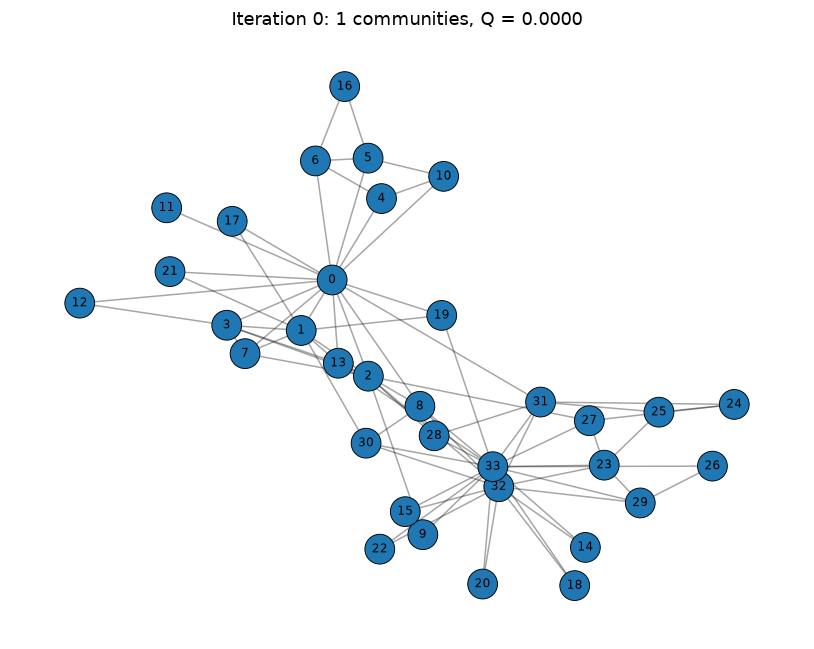

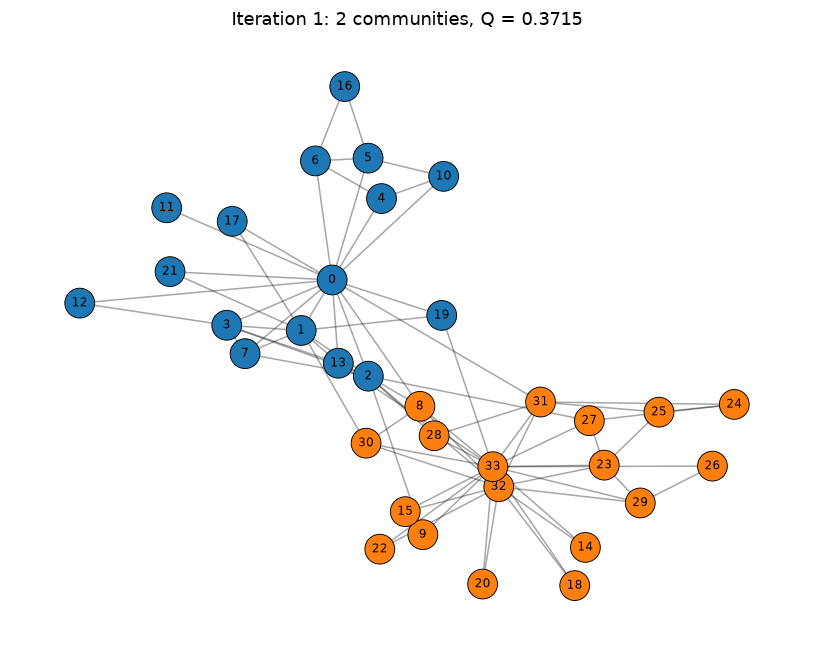

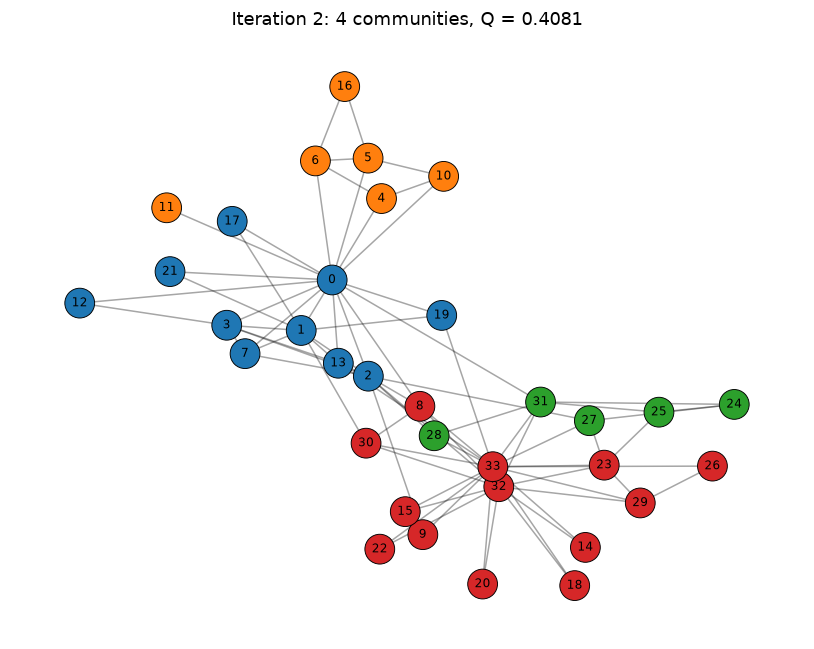

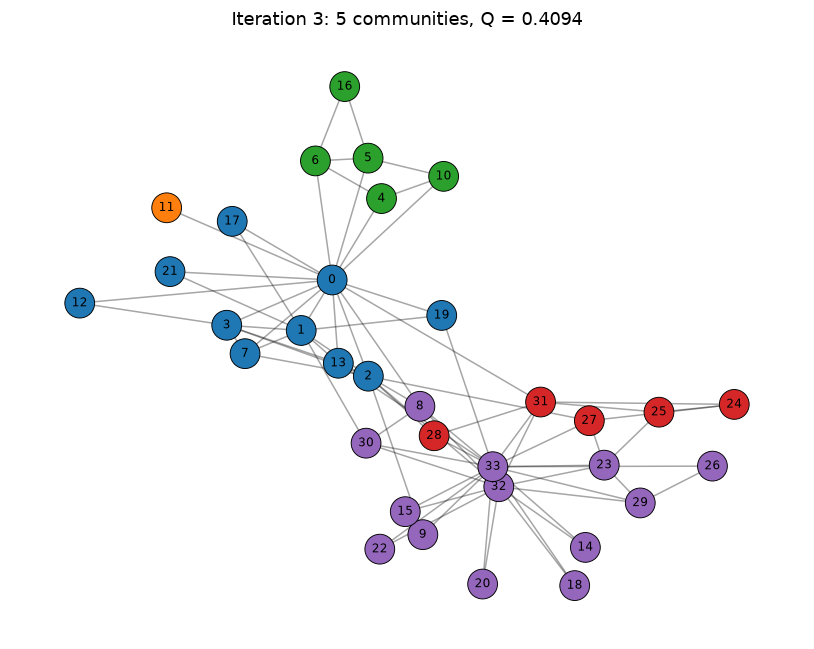

In [5]:
pos = nx.spring_layout(G, seed=42)
palette = plt.cm.tab10.colors

def draw_partition(partition, title, fname=None):
    color_of = {v: palette[ci % len(palette)] for ci, C in enumerate(partition) for v in C}
    fig, ax = plt.subplots(figsize=(7.5, 6))
    nx.draw_networkx_edges(G, pos, alpha=0.35, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_color=[color_of[v] for v in G.nodes()],
                           node_size=380, edgecolors="black", linewidths=0.6, ax=ax)
    nx.draw_networkx_labels(G, pos, font_size=8, ax=ax)
    ax.set_title(title); ax.axis("off")
    plt.tight_layout()
    if fname: save_fig(fname)
    plt.show()

for t, part in enumerate(history):
    draw_partition(part, f"Iteration {t}: {len(part)} communities, Q = {Q_of(part):.4f}",
                   fname=f"partition_iter{t}")

## Comparing with the real split

G.nodes[i]['club'] stores whether member $i$ 
 followed Mr. Hi or the Officer (administrator).

In [6]:
truth = np.array([0 if G.nodes[i]["club"] == "Mr. Hi" else 1 for i in nodes])
pred = np.zeros(n, dtype=int)
for v in history[1][1]:
    pred[v] = 1
agree = (pred == truth).mean()
acc = max(agree, 1 - agree)                                   # invariant to label switching
wrong = [v for v in nodes if (pred[v] != truth[v]) == (agree >= 0.5)]
print(f"First bisection vs. real club split: accuracy = {acc:.3f}   misclassified node(s): {wrong}")

# How do the final communities sit relative to the two real factions?
for C in history[-1]:
    print(f"{C}\n   Mr. Hi: {sum(truth[v]==0 for v in C)}   Officer: {sum(truth[v]==1 for v in C)}")

First bisection vs. real club split: accuracy = 0.971   misclassified node(s): [8]
[0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
   Mr. Hi: 10   Officer: 0
[11]
   Mr. Hi: 1   Officer: 0
[4, 5, 6, 10, 16]
   Mr. Hi: 5   Officer: 0
[24, 25, 27, 28, 31]
   Mr. Hi: 0   Officer: 5
[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]
   Mr. Hi: 1   Officer: 12


# 4. Node Metrics after each iteration

After every iteration we compute, with NetworkX, **degree centrality, betweenness centrality, closeness centrality and the clustering coefficient** for every node.

**Design choice:** The graph never changes during the recursion, so metrics on the *whole* graph would be identical at every iteration. To make them respond to the community structure, at iteration $t$ each node's metrics are computed on **the subgraph induced by its own community** at that iteration. Iteration 0 equals the ordinary whole-graph values. Three consequences to keep in mind:
- values are normalized by the community size, so they tend to rise as communities shrink;
- a node whose neighbours are all in other communities has degree $<2$ inside its community, and NetworkX then defines its clustering as 0;
- a community with a single node gets degree centrality 1 (NetworkX convention) and the other three metrics 0.

In [7]:
METRICS = {
    "Degree centrality":      nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality":   nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

# metric_history[iteration][metric_name] -> {node: value}   (dictionary keyed by iteration)
metric_history = {}
for t, partition in enumerate(history):
    metric_history[t] = {name: {} for name in METRICS}
    for C in partition:
        H = G.subgraph(C)                       # induced subgraph of the community
        for name, fn in METRICS.items():
            metric_history[t][name].update(fn(H))

# One DataFrame per metric: rows = nodes, columns = iterations
metric_df = {
    name: pd.DataFrame({t: pd.Series(metric_history[t][name]) for t in metric_history}).sort_index()
    for name in METRICS
}

# Save everything in one tidy table
tidy = pd.concat({name.replace(" ", "_").lower(): df for name, df in metric_df.items()}, axis=1)
tidy.index.name = "node"
tidy.to_csv("outputs/node_metrics_by_iteration.csv")
metric_df["Degree centrality"].round(3).head(10)

,0,1,2,3
0,0.485,0.933,1.000,1.000
1,0.273,0.533,0.889,0.889
2,0.303,0.333,0.556,0.556
3,0.182,0.400,0.667,0.667
4,0.091,0.200,0.400,0.500
5,0.121,0.267,0.600,0.750
6,0.121,0.267,0.600,0.750
7,0.121,0.267,0.444,0.444
8,0.152,0.176,0.250,0.250
9,0.061,0.059,0.083,0.083


# 5. Evolution of metrics across iterations

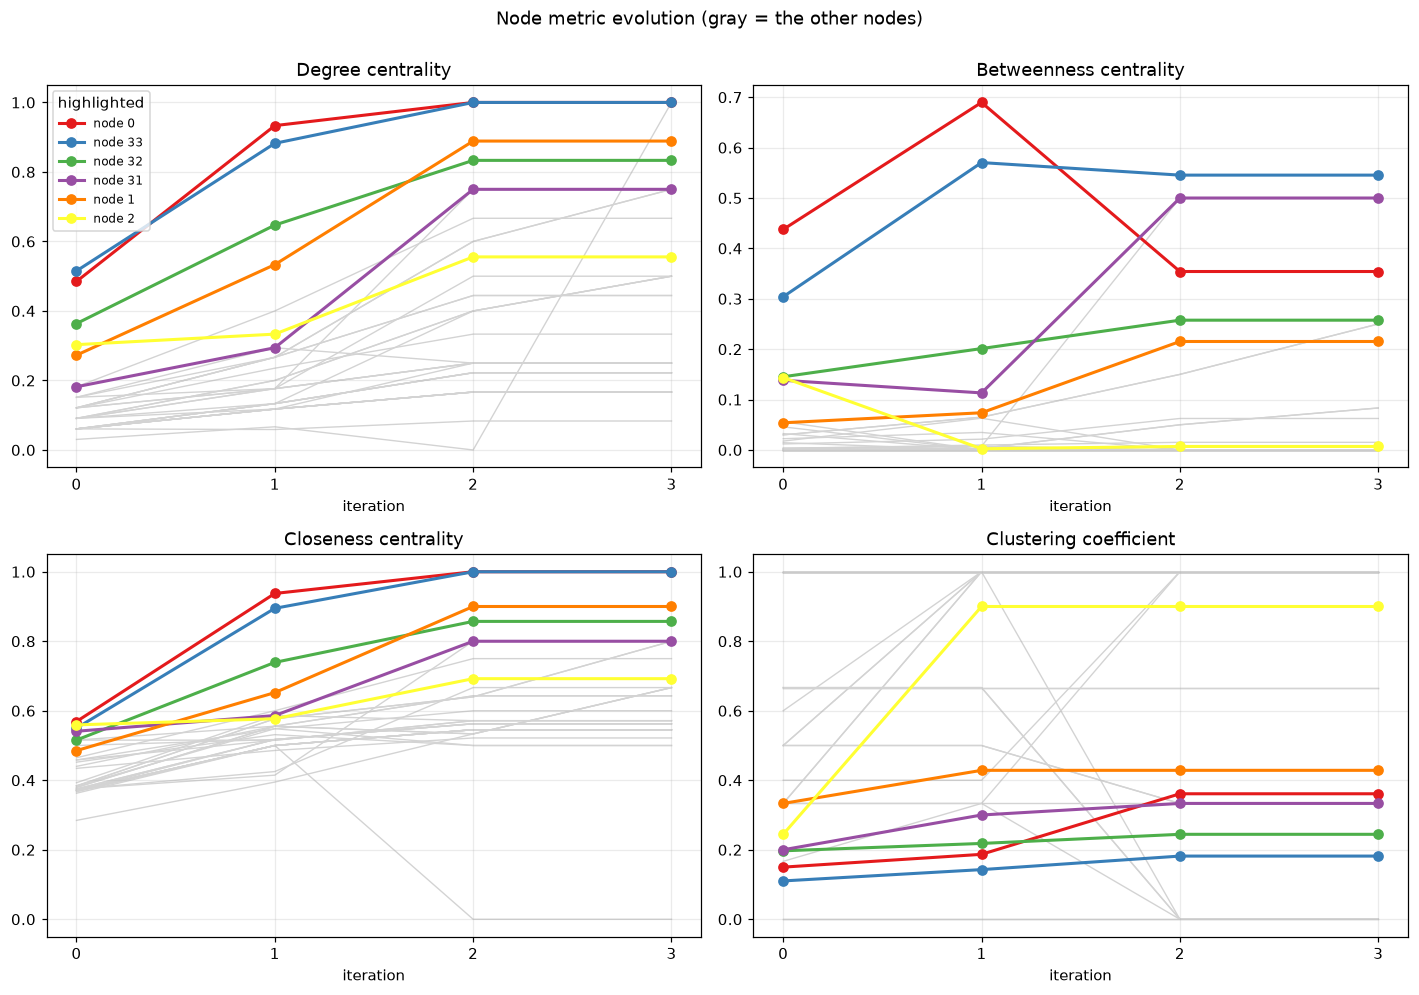

In [8]:
iters = list(range(len(history)))
highlight = [0, 33, 32, 31, 1, 2]          # the hubs plus nodes whose role changes most
hl_colors = dict(zip(highlight, plt.cm.Set1.colors))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (name, df) in zip(axes.ravel(), metric_df.items()):
    for v in df.index:
        if v not in highlight:
            ax.plot(iters, df.loc[v], color="lightgray", lw=0.9, zorder=1)
    for v in highlight:
        ax.plot(iters, df.loc[v], marker="o", lw=2, color=hl_colors[v], label=f"node {v}", zorder=3)
    ax.set_title(name); ax.set_xlabel("iteration"); ax.set_xticks(iters); ax.grid(alpha=0.25)
axes[0, 0].legend(title="highlighted", fontsize=8)
fig.suptitle("Node metric evolution (gray = the other nodes)", y=1.0)
plt.tight_layout(); save_fig("metric_evolution_lines"); plt.show()

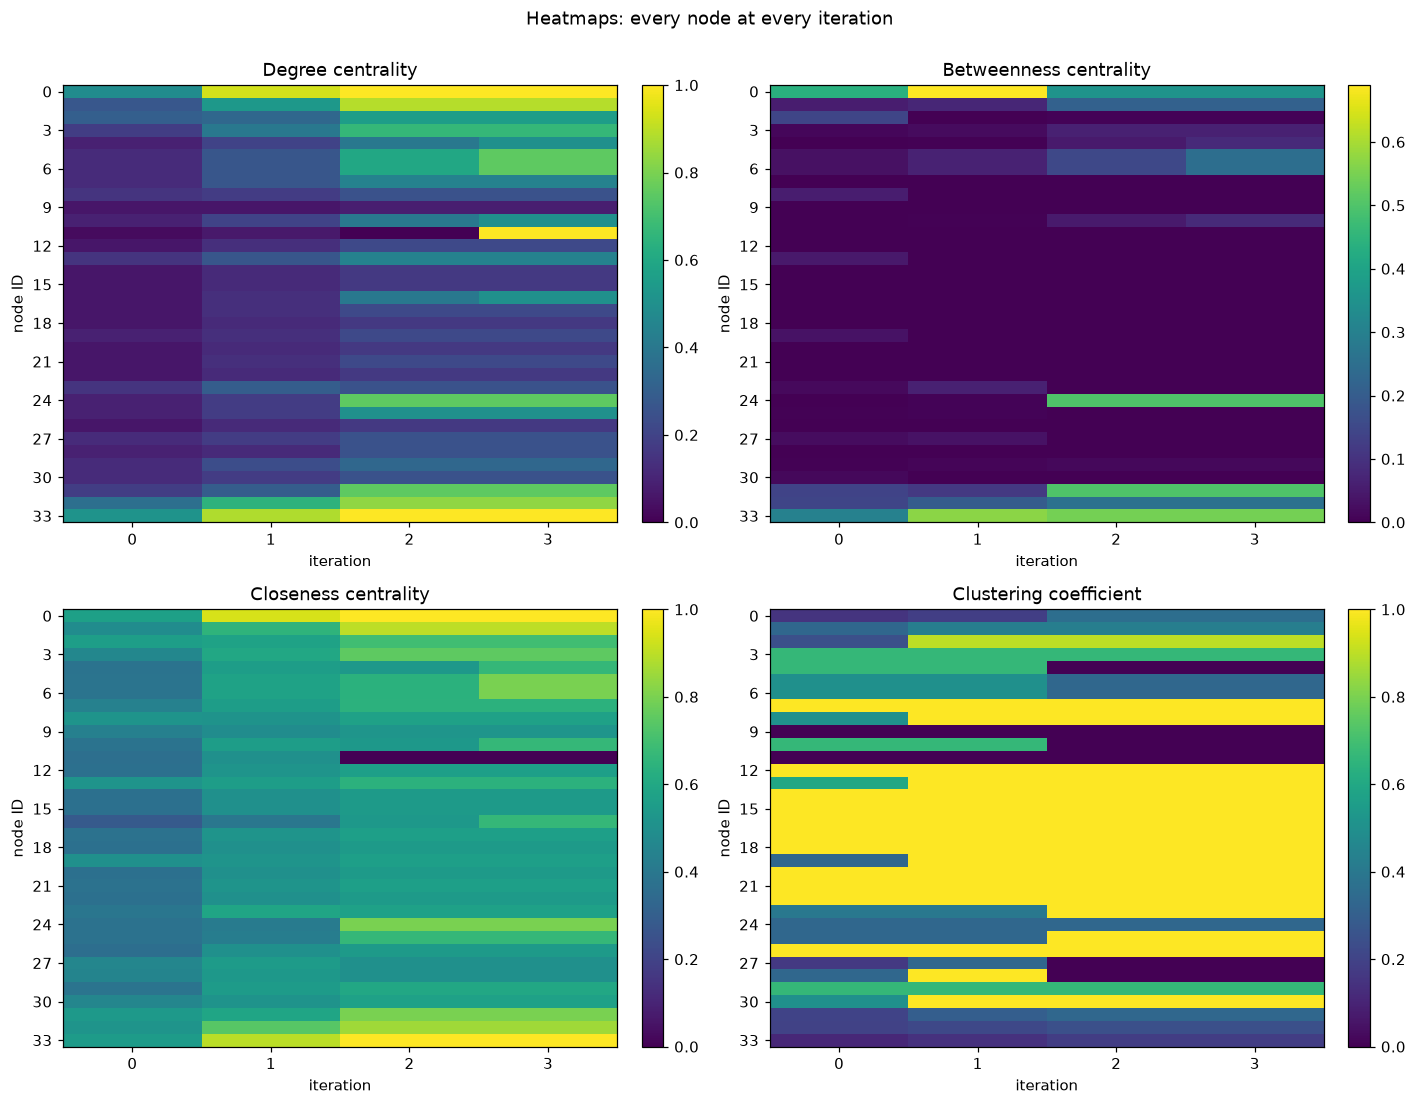

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
for ax, (name, df) in zip(axes.ravel(), metric_df.items()):
    im = ax.imshow(df.values, aspect="auto", cmap="viridis")
    ax.set_title(name); ax.set_xlabel("iteration"); ax.set_ylabel("node ID")
    ax.set_xticks(range(len(iters))); ax.set_xticklabels(iters)
    ax.set_yticks(range(0, n, 3)); ax.set_yticklabels(range(0, n, 3))
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("Heatmaps: every node at every iteration", y=1.0)
plt.tight_layout(); save_fig("metric_evolution_heatmaps"); plt.show()

In [10]:
# Which nodes are on top? (top-5 per metric, at each iteration and averaged over iterations)
top5 = pd.DataFrame({
    name: {**{f"iteration {t}": list(df[t].nlargest(5).index) for t in iters},
           "mean over iterations": list(df.mean(axis=1).nlargest(5).index)}
    for name, df in metric_df.items()
}).T
pd.set_option("display.max_colwidth", 60)
top5

,iteration 0,iteration 1,iteration 2,iteration 3,mean over iterations
Degree centrality,"[33, 0, 32, 2, 1]","[0, 33, 32, 1, 3]","[0, 33, 1, 32, 24]","[0, 11, 33, 1, 32]","[0, 33, 32, 1, 31]"
Betweenness centrality,"[0, 33, 32, 2, 31]","[0, 33, 32, 31, 1]","[33, 24, 31, 0, 32]","[33, 24, 31, 0, 32]","[33, 0, 31, 24, 32]"
Closeness centrality,"[0, 2, 33, 31, 8]","[0, 33, 32, 1, 3]","[0, 33, 1, 32, 24]","[0, 33, 1, 32, 5]","[0, 33, 32, 1, 31]"
Clustering coefficient,"[7, 12, 14, 15, 16]","[7, 8, 12, 13, 14]","[7, 8, 12, 13, 14]","[7, 8, 12, 13, 14]","[7, 12, 14, 15, 16]"


# 6. Using Newman's refined stopping rule

Using the split rule :
split while $\lambda_1^{(C)}>0$ ends with **5** communities. 

This section checks whether that count is a property of the data or of the stopping rule. This section is a comparison with Newman (2006).

Two refinements are tested:
1. **Generalized matrix** $B^{(g)}_{ij}=B_{ij}-\delta_{ij}\sum_{l\in C}B_{il}$ (Newman 2006, Eq. 6), which gives the *exact* change in $Q$ for splitting a sub-community.
2. **Exact gain check:** accept a split only if $\Delta Q=\frac1{4m}s^\top B^{(g)}s>0$ for the **rounded** $\pm1$ vector $s$. ($\lambda_1>0$ guarantees a gain only for the real-valued eigenvector; rounding can remove it.)

In [11]:
variants = [("A. main result",                     dict(generalized=False, require_gain=False)),
            ("B. generalized B^(g), lambda1 > 0 only",            dict(generalized=True,  require_gain=False)),
            ("C. generalized B^(g) + dQ > 0 (Newman's full rule)", dict(generalized=True,  require_gain=True)),
            ("D. main_result matrix + dQ > 0 check",                  dict(generalized=False, require_gain=True))]
rows, variant_hist = [], {}
for name, kw in variants:
    h, _ = recursive_bisection(**kw)
    variant_hist[name] = h
    rows.append({"variant": name, "communities": len(h[-1]),
                 "Q per iteration": [round(Q_of(p), 4) for p in h],
                 "final sizes": sorted(len(C) for C in h[-1])})
pd.DataFrame(rows)

,variant,communities,Q per iteration,final sizes
0,A. main result,5,"[0.0, 0.3715, 0.4081, 0.4094]","[1, 5, 5, 10, 13]"
1,"B. generalized B^(g), lambda1 > 0 only",5,"[0.0, 0.3715, 0.3934, 0.3776]","[4, 5, 6, 7, 12]"
2,C. generalized B^(g) + dQ > 0 (Newman's full rule),4,"[0.0, 0.3715, 0.3934]","[6, 7, 9, 12]"
3,D. main_result matrix + dQ > 0 check,5,"[0.0, 0.3715, 0.4081, 0.4094]","[1, 5, 5, 10, 13]"


In the final round, the earlier split rule splits the community {4, 5, 6, 10, 11, 16} (λ₁ ≈ 2.15 > 0) and separates node 11 from the rest. Node 11 has a single neighbour, node 0, which lies in a different community, so within its own community it has no edges. The split is allowed by the rule and does increase modularity, but only marginally (Q rises from 0.4081 to 0.4094, a gain of 0.0013), and it produces a singleton. The 5th community is therefore a very weak refinement rather than a substantial new group. For comparison, Newman’s refined rule (generalized matrix and ΔQ > 0 check) does not make this split and stops at 4 communities.

Last split of the earlier splitting rule: {'iteration': 3, 'parent': [4, 5, 6, 10, 11, 16], 'lambda1': 2.148, 'sizes': (1, 5)}
Q before: 0.4081   Q after: 0.4094   gain = 0.0013
Node 11's neighbours: [0] -> its community in iteration 2: [4, 5, 6, 10, 11, 16]


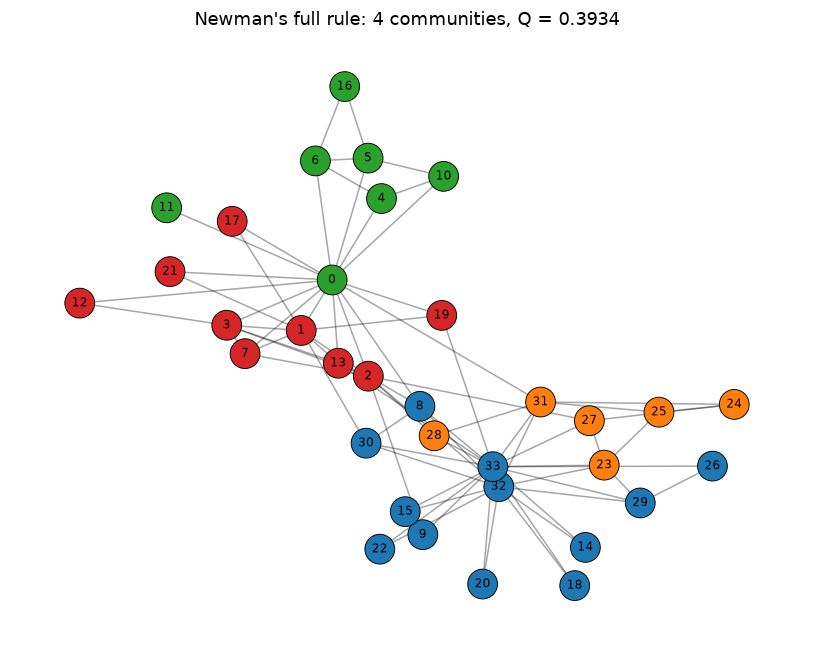

In [12]:
hA = variant_hist["A. main result"]
last = split_log.to_dict("records")[-1]
print("Last split of the earlier splitting rule:", last)
print(f"Q before: {Q_of(hA[-2]):.4f}   Q after: {Q_of(hA[-1]):.4f}   gain = {Q_of(hA[-1]) - Q_of(hA[-2]):.4f}")
print("Node 11's neighbours:", list(G[11]), "-> its community in iteration 2:",
      [C for C in hA[-2] if 11 in C][0])
hC = variant_hist["C. generalized B^(g) + dQ > 0 (Newman's full rule)"]
draw_partition(hC[-1], f"Newman's full rule: {len(hC[-1])} communities, Q = {Q_of(hC[-1]):.4f}", fname="partition_newman_rule")

# 7. Discussion

In the method used first, a group of nodes is split whenever the leading eigenvalue (λ₁) of its modularity matrix is positive, and it is left alone when λ₁ is zero or negative. Following this rule exactly, the club is first split into two groups, then into four, and in the last round the group {4, 5, 6, 10, 11, 16} still has a positive λ₁ (about 2.15), so the rule splits it again and separates node 11 from the rest. Node 11 has only one friend, node 0, who lies in a different group, so inside its own group it has no connections at all. This final split increases modularity by only 0.0013 (from 0.4081 to 0.4094), but because the rule only asks for λ₁ > 0, even a tiny improvement is accepted, and this gives 5 communities.

Newman’s correction makes two changes. First, for a smaller group it uses a corrected matrix (B⁽ᵍ⁾, obtained by subtracting each row sum from the diagonal of the block), which measures the exact change in modularity from splitting that group, since the plain block ignores the edges leaving the group. Second, it adds a stricter check: a positive λ₁ only promises a gain for the ideal eigenvector with any real values, but we round it to +1 and −1, and rounding can remove the gain, so a split is accepted only if the actual +1/−1 split has a positive modularity change (ΔQ > 0).

It was found that both changes are needed: with the corrected matrix alone the method still gives 5 communities, and modularity actually drops in the last round (from 0.393 to 0.378), which shows that λ₁ > 0 on its own is not a reliable test. With both changes, the algorithm stops at 4 communities (sizes 6, 7, 9 and 12, with Q ≈ 0.393). The corrected matrix also changes which groups form in the second round, so the 4-community result is a different partition from the first four groups of the first splitting method, and it has a slightly lower modularity than the 5-community result (0.393 compared with 0.409). This shows that the number of communities depends on the splitting rule as well as on the network itself.

### Which nodes remain central?
- Nodes 0 (Mr. Hi), 33 (the administrator), 32 and 1 are in the top 5 by degree centrality at every iteration, and nodes 0 and 33 are also in the top 5 for betweenness and closeness at every iteration. Nodes 0 and 33 are the leaders of the two factions and keep their hub role in every sub-community: in iteration 2 both are adjacent to every other member of their communities (degree and closeness 1.0). The only top-5 intruder is node 11 at iteration 3.
- **Roles that appear after splitting.** Nodes 24 and 31 have almost no betweenness in the full graph (0.002 and 0.138) but reach 0.50 each in the community {24, 25, 27, 28, 31}, where they are the two brokers. Node 1 rises from 0.05 to 0.22 in betweenness and from 0.27 to 0.89 in degree.
- **Roles that disappear.** Node 2 is the fourth most "between" node in the full graph (0.144), but its betweenness falls to about 0.00 once the factions are separated: its importance came from bridging the two factions, not from its position within its own group. Node 8 (the misclassified member) falls from 0.056 to 0 for the same reason.

### How community structure influences the metrics

- As communities shrink, degree centrality and closeness centrality increase. The metrics are computed inside each community and normalized by its size. So the nodes look better connected and closer to the others in a smaller group. Across the iterations, Node 0's degree centrality goes from 0.48 -> 0.93 -> 1.0 and Node 33's goes from 0.52 ->0.88 ->1.0 . This is due to normalization.
- Betweenness centrality identifies the local brokers(bridging nodes) and shows who held the groups together. Node 0's betweenness rises from 0.44 to 0.69 when the graph is divided into two groups(iteration 1), then falls to 0.35 when its group is split further.
- The clustering coefficient measures the tendency of nodes to form tightly knit groups. In the graph, the hubs keep low values(node 33: 0.11 → 0.18; node 0: 0.15 → 0.36; node 32: 0.20 → 0.24) because their neighbours are not connected to each other, while members of cliques (nodes 7 and 12) stay at 1.0. Splitting raises clustering for nodes whose neighbours stay together (node 2: 0.24 → 0.90; node 23: 0.40 → 1.0) and can lower it for nodes whose neighbours are cut away (node 4: 0.67 → 0 in iteration 2, because its two remaining neighbours in the community are not adjacent).
- Node 11 shows degree 0.07 → 0 → 1.0 and closeness 0.5 → 0 → 0. In iteration 2 it has no neighbours inside its community, and in iteration 3 it is a singleton, for which NetworkX returns degree centrality 1.0 by convention. Such values reflect the definitions, not any real change in the node's importance.


### Conclusions

In this assignment, recursive spectral modularity partitioning was implemented on Zachary’s Karate Club graph to identify community structure in a social network. The first split divides the club into two groups that match the real split for 33 of 34 members (only node 8 is misplaced). Continuing the recursion gives 5 communities (Q ≈ 0.409), which are nested within the two real factions apart from node 8. The communities beyond two are small refinements; the last one, the singleton node 11, adds only 0.0013 to Q. Newman’s refined rule gives 4 communities, which shows that the number of communities depends on the splitting rule as well as on the network. Nodes 0, 33, 32 and 1 remain among the most connected nodes throughout, with 0 and 33 also leading in betweenness and closeness, while the bridging roles of nodes 2 and 8 weaken and those of nodes 24 and 31 strengthen as the network is divided.

Overall, the results show that recursive spectral modularity partitioning recovers the known community structure of the Karate Club network well. The centrality and clustering analysis shows how node importance changes as the network is divided into smaller communities, although part of the rise in degree and closeness reflects the smaller community sizes.

# References
- Newman, M. E. J. (2006). *Modularity and community structure in networks.* Proceedings of the National Academy of Sciences, 103(23), 8577–8582.
- Zachary, W. W. (1977). *An information flow model for conflict and fission in small groups.* Journal of Anthropological Research, 33(4), 452–473.
- Course Handout: Modularity on the Karate Club Graph
